# Fig S12 (draft) · Lymph node 5k: block structure with the top-400 variable and the top-400 expressed genes

Fig S1 for lymph node 5k, one row per gene choice: the index's (top 400 by variance) and the 400 genes with the
highest mean count, each with its own production layout (seed 0).

* **A, C** the largest niche's mean correlation matrix in its gene order, whole (left) and the block-diagonal part
  that d_B uses (right).
* **B, D** every index tile: its mean |r| over the gene pairs inside blocks and over those between blocks (the entries
  d_B leaves out), histogram over the index tiles. Pairs with a gene without counts in the tile are left out.

Same layout, colours and colour scale as Fig S1.

**Run first:** `R14_ln5k_gene_choice` (`results/ln5k_gene_choice/tile_means.csv`, `niche_example_{var,mean}.npz`).
Writes `figures/figS12_ln5k_gene_choice/`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import numpy as np
import pandas as pd
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.patches import Patch, Rectangle

import style as ps

FIG = "figS12_ln5k_gene_choice"
RES = ROOT / "results" / "ln5k_gene_choice"
BLOCKS, FULL = ps.TIER_COLORS["spindle"], ps.MUTED   # as Fig S1
CMAP = "RdBu_r"
CLIM = 1.0                                            # as Fig S1
H = 58.0
SCENARIOS = {"var": "Top-400 variable genes", "mean": "Top-400 expressed genes"}

means = pd.read_csv(RES / "tile_means.csv")
ex = {sc: np.load(RES / f"niche_example_{sc}.npz") for sc in SCENARIOS}
genes = pd.read_csv(RES / "genes.csv")
EDGES = np.linspace(0, np.ceil(means[["mean_within", "mean_between"]].max().max() * 20) / 20, 41)  # shared by B, D
print(f"genes in both: {len(set(genes.gene[genes.scenario == 'var']) & set(genes.gene[genes.scenario == 'mean']))} of 400")

genes in both: 365 of 400


## A, C · the largest niche: mean correlation matrix and its block-diagonal part

figures/figS12_ln5k_gene_choice/panels/A.pdf/.png: 78 x 58 mm, 0.2 / 0.5 MB
figures/figS12_ln5k_gene_choice/panels/C.pdf/.png: 78 x 58 mm, 0.2 / 0.5 MB


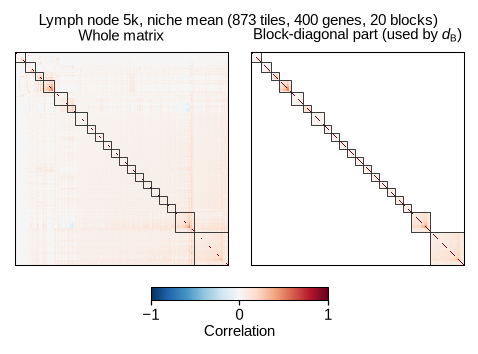

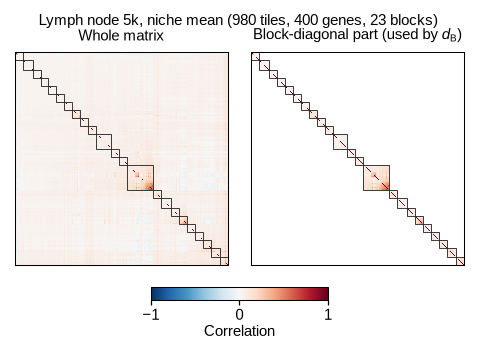

In [2]:
def panel_matrix(fig, sc):
    e = ex[sc]
    C, runs = e["corr"].astype(float), e["runs"]
    p = len(C)
    mask = np.zeros_like(C, bool)
    for s, t in runs:
        mask[s:t, s:t] = True
    W, Hp = ps.size_mm(fig)
    side = 36.0
    for j, (M, title) in enumerate(((C, "Whole matrix"), (np.where(mask, C, np.nan), "Block-diagonal part (used by $d_{\\mathcal{B}}$)"))):
        x = 1.0 + j * (side + 4.0)
        ax = fig.add_axes([x / W, 1 - (7.0 + side) / Hp, side / W, side / Hp])
        ax.imshow(M, cmap=CMAP, vmin=-CLIM, vmax=CLIM, interpolation="nearest")
        for s, t in runs:
            ax.add_patch(Rectangle((s - 0.5, s - 0.5), t - s, t - s, fill=False, lw=0.4, ec=ps.INK))
        ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(True); sp.set_linewidth(0.5)
        fig.text((x + side / 2) / W, 1 - 5.5 / Hp, title, ha="center", va="bottom", fontsize=ps.TICK_PT)
    fig.text(5.0 / W, 1 - 0.5 / Hp, f"Lymph node 5k, niche mean ({int(e['n_tiles']):,} tiles, {p} genes, "
             f"{len(runs)} blocks)", va="top", fontsize=ps.TICK_PT)
    cax = fig.add_axes([24.0 / W, 1 - (7.0 + side + 6.0) / Hp, 30.0 / W, 2.2 / Hp])
    cb = fig.colorbar(ScalarMappable(Normalize(-CLIM, CLIM), CMAP), cax=cax, orientation="horizontal",
                      ticks=[-CLIM, 0, CLIM])
    cb.outline.set_linewidth(0.5)
    cb.set_label("Correlation", fontsize=ps.TICK_PT, labelpad=1)


for letter, sc in zip("AC", SCENARIOS):
    fig = ps.panel(78, H); panel_matrix(fig, sc); ps.save_panel(fig, FIG, letter)

## B, D · every index tile: mean |r| within and between blocks

var, 6972 index tiles: within 0.122 +- 0.025, between 0.085 +- 0.011; within > between in 100 % of tiles
figures/figS12_ln5k_gene_choice/panels/B.pdf/.png: 56 x 58 mm, 0.0 / 0.2 MB
mean, 6972 index tiles: within 0.113 +- 0.019, between 0.086 +- 0.011; within > between in 100 % of tiles
figures/figS12_ln5k_gene_choice/panels/D.pdf/.png: 56 x 58 mm, 0.0 / 0.2 MB


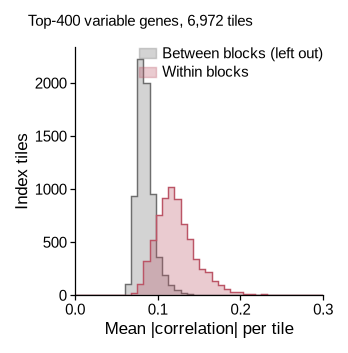

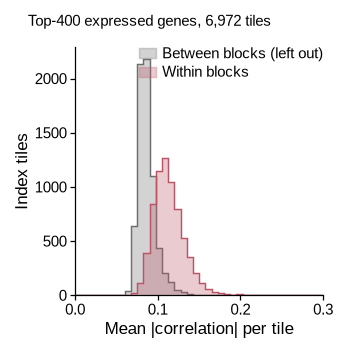

In [3]:
def panel_hist(fig, sc):
    ax = ps.axes(fig, left=12.0, right=2.0, bottom=10.0, top=6.0)
    m = means[means.scenario == sc]
    handles = []
    for part, color, label in (("between", FULL, "Between blocks (left out)"), ("within", BLOCKS, "Within blocks")):
        n, _ = np.histogram(m[f"mean_{part}"], EDGES)
        ax.stairs(n, EDGES, fill=True, color=color, alpha=0.3, lw=0)
        ax.stairs(n, EDGES, color=color, lw=0.7)
        handles.append(Patch(fc=color, alpha=0.3, ec=color, lw=0.7, label=label))
    print(f"{sc}, {len(m)} index tiles: within {m.mean_within.mean():.3f} +- {m.mean_within.std():.3f}, "
          f"between {m.mean_between.mean():.3f} +- {m.mean_between.std():.3f}; "
          f"within > between in {100 * (m.mean_within > m.mean_between).mean():.0f} % of tiles")
    ax.set_xlim(0, EDGES[-1])
    ax.set_ylim(0, None)
    ax.set_xlabel("Mean |correlation| per tile")
    ax.set_ylabel("Index tiles")
    ax.legend(handles=handles, loc="upper right")
    W, Hp = ps.size_mm(fig)
    fig.text(4.0 / W, 1 - 0.5 / Hp, f"{SCENARIOS[sc]}, {len(m):,} tiles", va="top", fontsize=ps.TICK_PT)


for letter, sc in zip("BD", SCENARIOS):
    fig = ps.panel(56, H); panel_hist(fig, sc); ps.save_panel(fig, FIG, letter)

## Full figure

var, 6972 index tiles: within 0.122 +- 0.025, between 0.085 +- 0.011; within > between in 100 % of tiles
mean, 6972 index tiles: within 0.113 +- 0.019, between 0.086 +- 0.011; within > between in 100 % of tiles
figures/figS12_ln5k_gene_choice/figS12_ln5k_gene_choice.pdf/.png: 136 x 116 mm, 0.4 / 1.4 MB


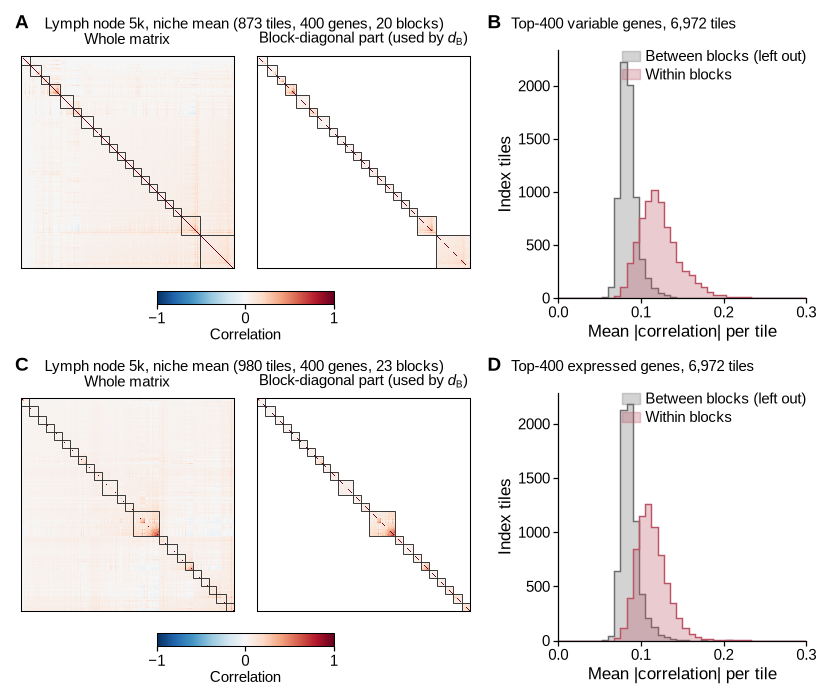

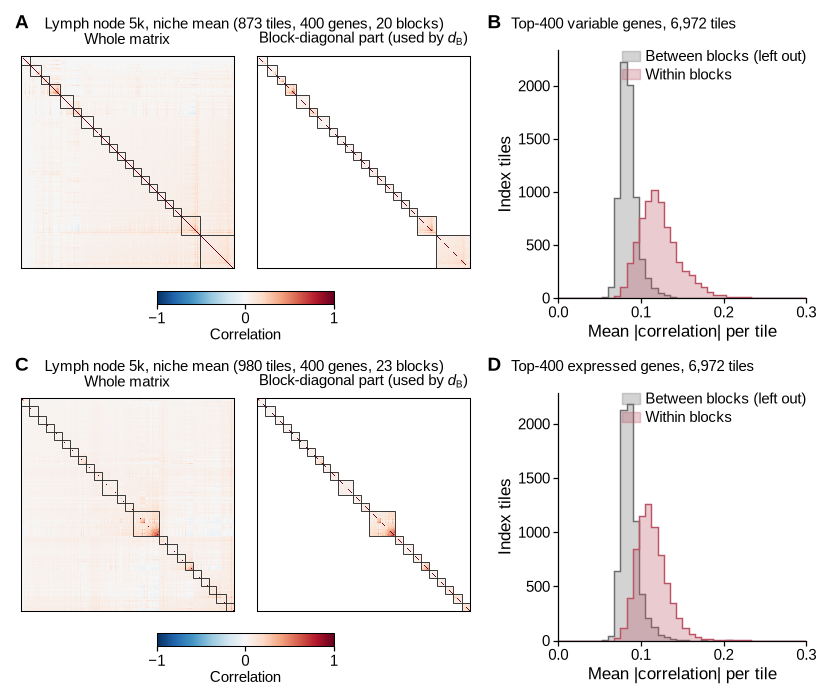

In [4]:
page = ps.page(136, 2 * H)
for i, (a, b, sc) in enumerate(zip("AC", "BD", SCENARIOS)):
    panel_matrix(ps.place(page, a, 0, i * H, 78, H), sc)
    panel_hist(ps.place(page, b, 80, i * H, 56, H), sc)
ps.save_figure(page, FIG)
page